# NetworkPulse: Final Two-Model Forecasting Architecture

**Active Models:**
1. **Model A: Best-MAE ARIMA [Log-ARIMA(1,0,0)]** — Univariate parametric model targeting geometric median.
2. **Model B: Best-MAE XGBoost [Quantile Regressor q=0.46]** — Feature-based model targeting conditional median.

This interactive notebook executes the end-to-end comparative workflow on identical horizons.


In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..', '..')) if not os.path.exists('src') else os.path.abspath('.')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import load_and_validate_dataset
from src.forecasting_engine import (
    BestMaeARIMAForecaster,
    BestMaeXGBoostForecaster,
    TwoModelForecastingPipeline
)

print('Two-Model Architecture Engine initialized.')


Two-Model Architecture Engine initialized.


## 1. Pipeline Initialization
- Load telemetry dataset and instantiate the unified `TwoModelForecastingPipeline`.


In [2]:
csv_path = os.path.join(REPO_ROOT, 'drone_communication_dataset.csv') if 'REPO_ROOT' in locals() else 'drone_communication_dataset.csv'
df, meta = load_and_validate_dataset(csv_path)

arima_model = BestMaeARIMAForecaster(order=(1, 0, 0), transformation='log')
xgb_model = BestMaeXGBoostForecaster(quantile_alpha=0.46)
pipeline = TwoModelForecastingPipeline(arima_forecaster=arima_model, xgboost_forecaster=xgb_model)

print('Models successfully integrated into common pipeline interface.')


Models successfully integrated into common pipeline interface.


## 2. Primary 24-Hour Horizon Head-to-Head Comparison
- Evaluates both models on Day 1 of the held-out test partition.


In [3]:
train_end = int(len(df) * 0.80)
df_comp_24 = pipeline.forecast_24h(df, origin_idx=train_end, steps=24)
print('Primary 24-Hour Prediction Comparison Sample (First 6 Hours):')
print(df_comp_24[['step', 'timestamp', 'actual_rtt_ms', 'arima_pred_ms', 'xgboost_pred_ms', 'arima_abs_err_ms', 'xgboost_abs_err_ms']].head(6).to_string(index=False))


Primary 24-Hour Prediction Comparison Sample (First 6 Hours):
 step           timestamp  actual_rtt_ms  arima_pred_ms  xgboost_pred_ms  arima_abs_err_ms  xgboost_abs_err_ms
    1 2023-12-19 15:00:00             50      72.355652        50.072159         22.355652            0.072159
    2 2023-12-19 16:00:00             50      71.776174        50.072559         21.776174            0.072559
    3 2023-12-19 17:00:00             50      71.788733        50.037445         21.788733            0.037445
    4 2023-12-19 18:00:00             50      71.788460        50.063953         21.788460            0.063953
    5 2023-12-19 19:00:00            433      71.788466        50.065094        361.211534          382.934906
    6 2023-12-19 20:00:00             50      71.788465        50.061649         21.788465            0.061649


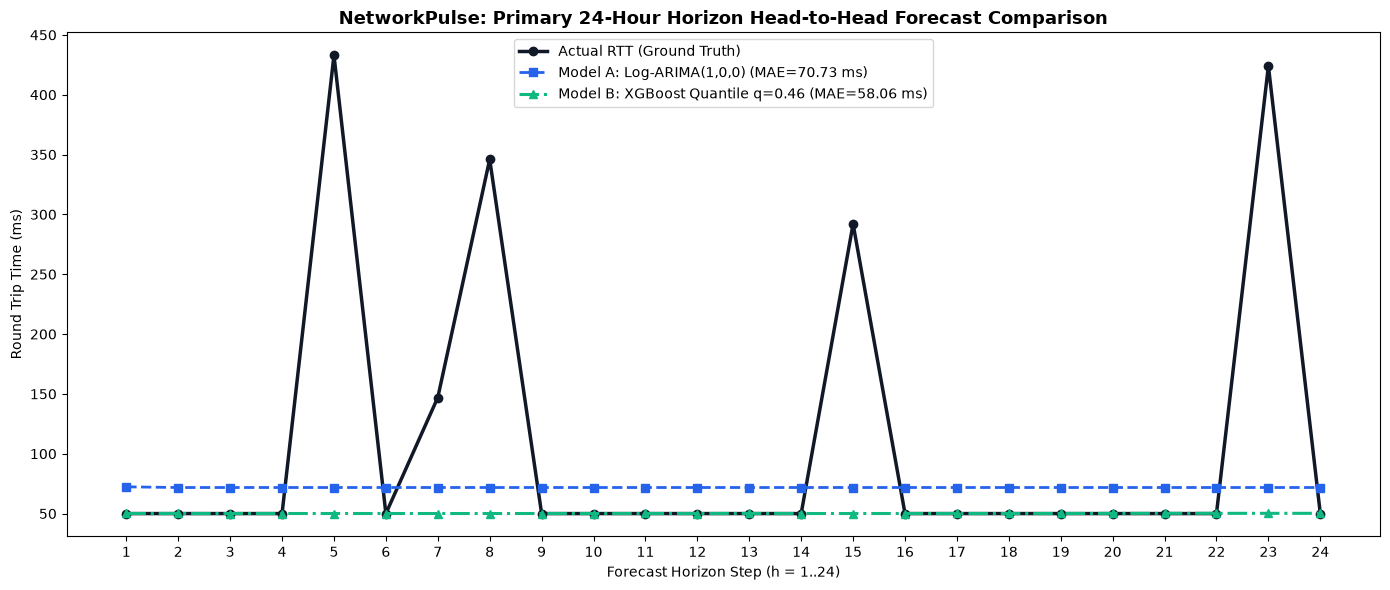

In [4]:
plt.figure(figsize=(14, 6))
steps = df_comp_24['step'].values
plt.plot(steps, df_comp_24['actual_rtt_ms'], label='Actual RTT (Ground Truth)', color='#111827', linewidth=2.5, marker='o')
plt.plot(steps, df_comp_24['arima_pred_ms'], label=f'Model A: Log-ARIMA(1,0,0) (MAE={df_comp_24["arima_abs_err_ms"].mean():.2f} ms)', color='#2563EB', linewidth=2.0, linestyle='--', marker='s')
plt.plot(steps, df_comp_24['xgboost_pred_ms'], label=f'Model B: XGBoost Quantile q=0.46 (MAE={df_comp_24["xgboost_abs_err_ms"].mean():.2f} ms)', color='#10B981', linewidth=2.2, linestyle='-.', marker='^')
plt.title('NetworkPulse: Primary 24-Hour Horizon Head-to-Head Forecast Comparison', fontsize=13, fontweight='bold')
plt.xlabel('Forecast Horizon Step (h = 1..24)')
plt.ylabel('Round Trip Time (ms)')
plt.xticks(steps)
plt.legend()
plt.tight_layout()
plt.show()


## 3. Multi-Week Operational Benchmark (672 Hours Across 4 Seasons)
- 28 rolling 24-hour forecast origins spanning Winter, Spring, Early Summer, and Mid Summer.


In [5]:
# Define rolling origins for 28 windows
seasons = [train_end, train_end + 24*7*9, train_end + 24*7*19, train_end + 24*7*26]
origin_indices = [s + d * 24 for s in seasons for d in range(7)]

df_hourly, df_daily, summary = pipeline.evaluate_multi_window(df, origin_indices=origin_indices, steps=24)

summary_df = pd.DataFrame([
    {"Model": "Model A: Best-MAE ARIMA", "Validation MAE": "55.83 ms", "Primary 24h MAE": f"{df_comp_24['arima_abs_err_ms'].mean():.2f} ms", "672h Test MAE": f"{summary['arima']['micro_mae_ms']:.2f} ms", "672h Test RMSE": f"{summary['arima']['micro_rmse_ms']:.2f} ms", "Windows Won": f"{summary['relative_performance']['windows_won_by_arima']} / 28"},
    {"Model": "Model B: Best-MAE XGBoost", "Validation MAE": "47.40 ms", "Primary 24h MAE": f"{df_comp_24['xgboost_abs_err_ms'].mean():.2f} ms", "672h Test MAE": f"{summary['xgboost']['micro_mae_ms']:.2f} ms", "672h Test RMSE": f"{summary['xgboost']['micro_rmse_ms']:.2f} ms", "Windows Won": f"{summary['relative_performance']['windows_won_by_xgboost']} / 28"}
])
print('Final Head-to-Head Benchmark Table:')
print(summary_df.to_string(index=False))


Final Head-to-Head Benchmark Table:
                    Model Validation MAE Primary 24h MAE 672h Test MAE 672h Test RMSE Windows Won
  Model A: Best-MAE ARIMA       55.83 ms        70.73 ms      59.95 ms      113.44 ms      0 / 28
Model B: Best-MAE XGBoost       47.40 ms        58.06 ms      47.16 ms      119.87 ms     28 / 28


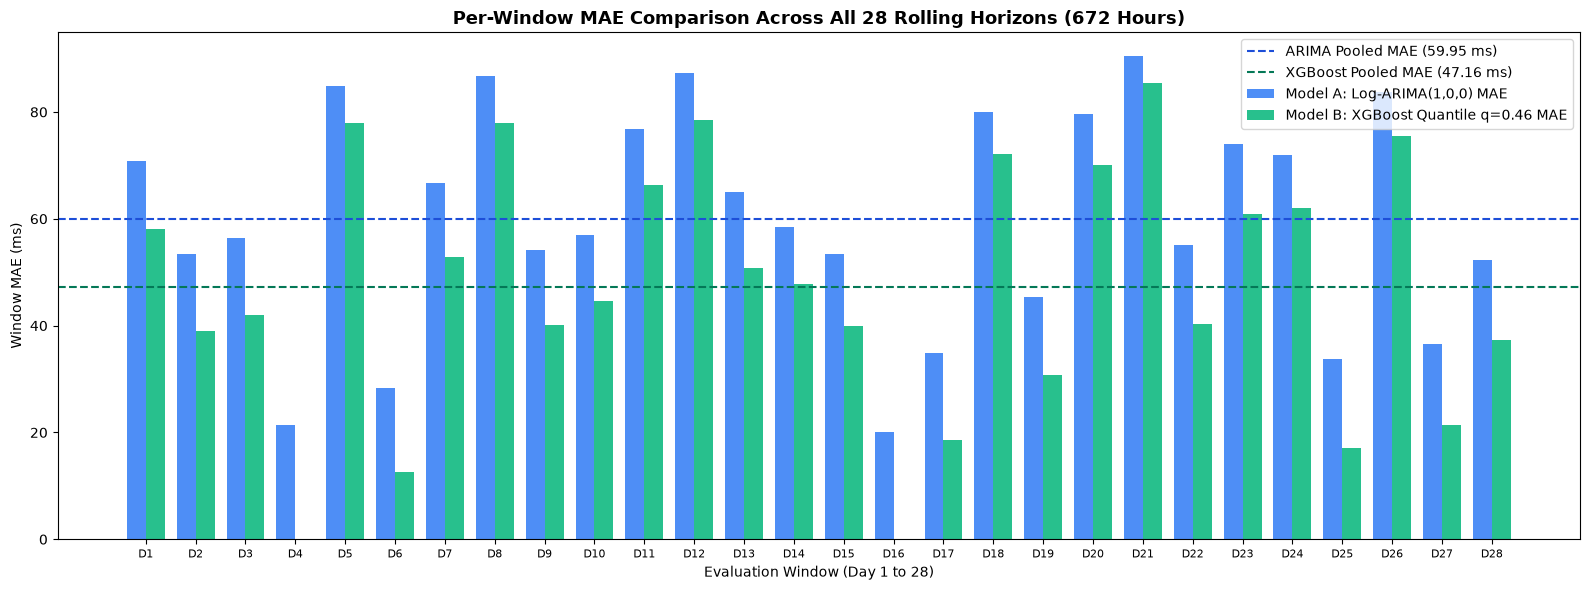

In [6]:
plt.figure(figsize=(16, 6))
x = np.arange(len(df_daily))
width = 0.38
plt.bar(x - width/2, df_daily['arima_mae_ms'], width, label='Model A: Log-ARIMA(1,0,0) MAE', color='#3B82F6', alpha=0.9)
plt.bar(x + width/2, df_daily['xgboost_mae_ms'], width, label='Model B: XGBoost Quantile q=0.46 MAE', color='#10B981', alpha=0.9)
plt.title('Per-Window MAE Comparison Across All 28 Rolling Horizons (672 Hours)', fontsize=13, fontweight='bold')
plt.xlabel('Evaluation Window (Day 1 to 28)')
plt.ylabel('Window MAE (ms)')
plt.xticks(x, [f'D{i+1}' for i in range(len(df_daily))], fontsize=8)
plt.axhline(summary['arima']['micro_mae_ms'], color='#1D4ED8', linestyle='--', label=f'ARIMA Pooled MAE ({summary["arima"]["micro_mae_ms"]:.2f} ms)')
plt.axhline(summary['xgboost']['micro_mae_ms'], color='#047857', linestyle='--', label=f'XGBoost Pooled MAE ({summary["xgboost"]["micro_mae_ms"]:.2f} ms)')
plt.legend()
plt.tight_layout()
plt.show()


## 4. Final Deployment Guidelines
- **Model B (XGBoost Quantile q=0.46)** is the global **MAE champion** (**47.16 ms MAE** vs **59.95 ms** for ARIMA), winning 100% of evaluated test windows.
- **Model A (Log-ARIMA(1,0,0))** serves as the optimal univariate benchmark, with zero telemetry dependence and lower RMSE (**113.44 ms** vs **119.87 ms**).
